
<img src="../../images/brownbear.png" width="400">

## A financial tool that can analyze and maximize investment portfolios on a risk adjusted basis  


Description: This notebook is useful for examining potfolios comprised of stocks from the S&P 600.  Construct portfolios from the 600 stocks in the S&P 600 small cap index and examine the results of different weighting schemes.


In [1]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import brownbear as bb

# format price data
pd.options.display.float_format = '{:0.2f}'.format

# display all rows
pd.set_option('display.max_rows', None)

# do not truncate column names
pd.set_option('display.max_colwidth', None)

%matplotlib inline

In [3]:
# set size of inline plots
'''note: rcParams can't be in same cell as import matplotlib
   or %matplotlib inline
   
   %matplotlib notebook: will lead to interactive plots embedded within
   the notebook, you can zoom and resize the figure
   
   %matplotlib inline: only draw static images in the notebook
'''
plt.rcParams["figure.figsize"] = (10, 7)

### Some Globals

In [4]:
investment_universe = ['sp600-galaxy']

In [5]:
# Fetch Investment Options - all values annualized
df = bb.fetch(investment_universe, risk_free_rate=0, annual_returns='3 Yr')
df

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
0,AAMI,Acadian Asset Management Inc.,US Stocks:Financials,209.16,218.19,89.80,90.84,64.87,29.77,22.91,9.09,34.46,36.23,37.37,64.87,36.23,1.79
1,AAP,"Advance Auto Parts, Inc.",US Stocks:Consumer Discretionary,-73.81,-33.72,-27.99,-25.99,-13.10,-25.41,95.67,84.71,51.36,56.46,51.59,-13.10,56.46,-739.63
2,AAT,American Assets Trust,US Stocks:Real Estate,-8.92,40.74,15.80,18.51,8.86,-4.87,19.27,13.19,23.16,25.18,27.68,8.86,25.18,0.35
3,ABCB,Ameris Bancorp,US Stocks:Financials,7.16,22.64,17.13,18.15,30.67,13.54,12.23,6.98,16.06,26.35,31.14,30.67,26.35,1.16
4,ABG,Asbury Automotive Group,US Stocks:Consumer Discretionary,61.54,-2.01,-17.53,-17.18,-1.62,2.64,26.90,14.44,24.45,33.44,35.36,-1.62,33.44,-54.17
5,ABM,"ABM Industries, Inc.",US Stocks:Industrials,118.87,15.71,-2.36,-0.99,3.83,1.61,15.33,7.51,26.18,25.46,25.51,3.83,25.46,0.15
6,ABR,Arbor Realty Trust,US Stocks:Financials,-31.61,-50.47,-51.17,-51.42,-21.70,-12.72,32.14,13.27,30.78,32.34,37.90,-21.70,32.34,-701.78
7,ACA,"Arcosa, Inc.",US Stocks:Industrials,72.83,82.99,46.80,47.40,24.06,23.84,2.76,1.68,25.68,29.47,28.61,24.06,29.47,0.82
8,ACAD,Acadia Pharmaceuticals,US Stocks:Healthcare,226.24,40.48,9.56,15.59,0.54,11.78,44.17,20.60,32.76,51.80,47.26,0.54,51.80,0.01
9,ACHC,Acadia Healthcare,US Stocks:Healthcare,129.34,48.35,28.66,40.23,-27.71,-14.70,55.49,37.67,85.29,63.08,52.46,-27.71,63.08,-1747.95


In [6]:
# Rank
rank = bb.rank(df, rank_by='Sharpe Ratio', group_by='Asset Subclass', num_per_group=1)
rank_filtered = rank
#rank_filtered = rank.loc[(rank['3 mo'] > 0) & rank['1 Yr'] > 0]
rank_filtered = rank_filtered.head(20)
rank_filtered

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
333,MDU,"MDU Resources Group, Inc.",US Stocks:Utilities,-20.23,-5.95,23.85,27.22,24.36,13.14,19.95,9.37,21.92,24.59,23.91,24.36,24.59,0.99
151,DBD,Diebold Nixdorf,US Stocks:Technology,-52.53,-29.12,6.92,7.77,48.66,48.66,39.08,25.62,27.43,36.40,36.40,48.66,36.40,1.34
137,CURB,Curbline Properties Corp.,US Stocks:Real Estate,14.92,19.13,35.54,36.62,35.54,35.54,14.52,8.94,18.13,17.29,17.29,35.54,17.29,2.06
106,CENX,Century Aluminum Company,US Stocks:Materials,-75.12,-18.35,105.24,104.41,82.06,34.11,60.35,32.56,54.19,59.12,69.37,82.06,59.12,1.39
561,VSTS,Vestis,US Stocks:Industrials,-12.94,151.47,171.30,180.84,171.30,171.30,27.32,19.47,46.71,53.57,53.57,171.30,53.57,3.20
435,PTGX,"Protagonist Therapeutics, Inc.",US Stocks:Healthcare,341.66,145.69,134.95,162.33,92.07,24.01,39.33,18.71,32.52,41.80,72.08,92.07,41.80,2.20
150,DAVE,"Dave, Inc.",US Stocks:Financials,222.14,283.63,82.16,79.63,281.46,3.63,91.02,66.32,72.56,135.33,130.32,281.46,135.33,2.08
284,KGS,"Kodiak Gas Services, Inc.",US Stocks:Energy,-42.92,14.91,69.55,79.77,55.01,55.01,46.22,27.14,42.60,36.02,35.77,55.01,36.02,1.53
110,CHEF,"Chefs' Warehouse, Inc.",US Stocks:Consumer Staples,409.61,159.49,83.68,76.37,59.07,32.11,27.66,16.04,45.89,46.03,44.27,59.07,46.03,1.28
296,LAUR,"Laureate Education, Inc.",US Stocks:Consumer Discretionary,116.41,43.94,41.92,43.74,42.04,39.80,23.66,14.13,28.50,24.16,28.71,42.04,24.16,1.74


### Sample Portfolios
Format 'Investment option': weight

In [7]:
# everything ranked
ranked_portfolio = {
    'Title': 'Ranked Portfolio'
}
everything = list(rank_filtered['Investment Option'])
ranked_portfolio.update(dict.fromkeys(everything, 1/len(everything)))

# top 10
top10_portfolio = {
    'Title': 'Ranked Portfolio'
}
top10 = list(rank_filtered['Investment Option'])[:10]
top10_portfolio.update(dict.fromkeys(top10, 1/len(top10)))

### Custom Portfolios

In [8]:
# My portfolio
my_portfolio = {
    'Title': 'My Portfolio',

}

### Choose Portfolio Option

In [9]:
# Select one of the portfolios from above
portfolio_option = ranked_portfolio

In [10]:
# Make a copy so that the original portfolio is preserved
portfolio_option = portfolio_option.copy()

### Analysis Options

In [11]:
# Specify the weighting scheme.  It will replace the weights specified in the portfolio
# You can also fix the weights on some Investent Options, Asset Classes, and Asset Subclasses
# while the others are automatically calculated.

# 'Equal' - will use equal weights.

# 'Sharpe Ratio' - will use proportionally weighted # allocations based on the percent
#  of an investment option's sharpe ratio to the sum of all the sharpe ratios in the portfolio.

# 'Std Dev' - will use standard deviation adjusted weights

# 'Annual Returns' - will use return adjusted weights

# 'Vola' - will use volatility adjusted weights

# 'DS Vola' - will use downside volatility adjusted weights

# None: 'Investment Option' means use user specified weights
#       'Asset Class' means do not group by Asset Class
#       'Asset Subclass means do not group by Asset Subclass 

weight_by = {
    'Asset Class':       {'weight_by': None},
    'Asset Subclass':    {'weight_by': None},
    'Investment Option': {'weight_by': 'DS Vola'},
}
#weight_by = None

In [12]:
bb.DEBUG = False

# Analyze portfolio
annual_ret, std_dev, sharpe_ratio = \
    bb.analyze(df, portfolio_option, weight_by)

,MDU,DBD,CURB,CENX,VSTS,PTGX,DAVE,KGS,CHEF,LAUR,MSGS,Ranked Portfolio
Annual Returns,24.36,48.66,35.54,82.06,171.30,92.07,281.46,55.01,59.07,42.04,30.36,61.93
Std Dev,24.59,36.40,17.29,59.12,53.57,41.80,135.33,36.02,46.03,24.16,20.51,20.10
Sharpe Ratio,0.99,1.34,2.06,1.39,3.20,2.20,2.08,1.53,1.28,1.74,1.48,3.08
Weight,0.16,0.06,0.16,0.05,0.08,0.08,0.02,0.06,0.10,0.11,0.12,1.00
Worst Typical Down Year,-24.82,-24.14,0.96,-36.18,64.16,8.47,10.80,-17.03,-32.99,-6.28,-10.66,21.72
Black Swan,-49.41,-60.54,-16.33,-95.30,10.59,-33.33,-124.53,-53.05,-79.02,-30.44,-31.17,1.62


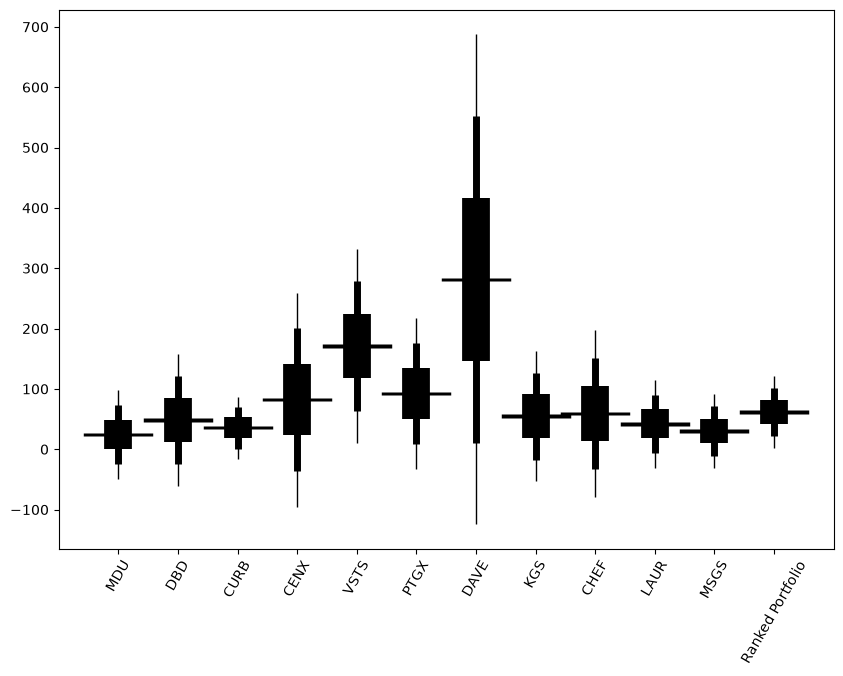

In [13]:
# Display Results
summary = bb.summary(df, portfolio_option, annual_ret, std_dev, sharpe_ratio)
summary

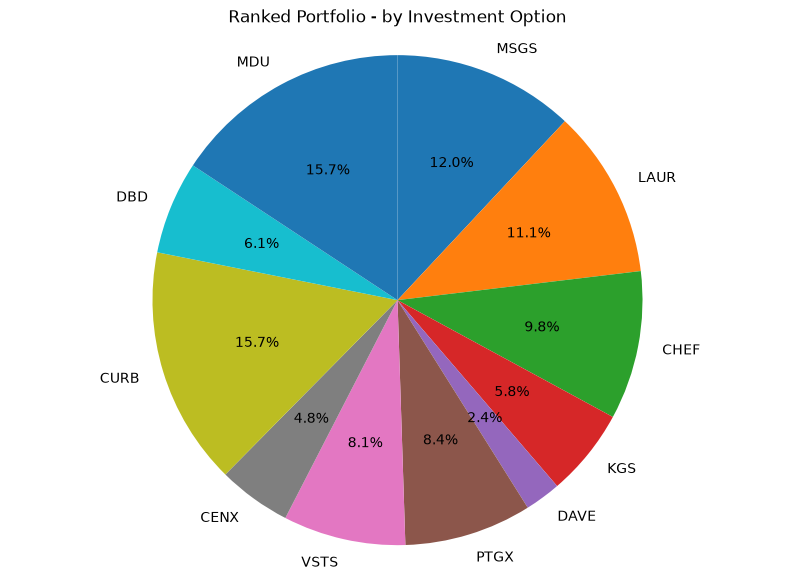

MSGS   0.12
LAUR   0.11
CHEF   0.10
KGS    0.06
DAVE   0.02
PTGX   0.08
VSTS   0.08
CENX   0.05
CURB   0.16
DBD    0.06
MDU    0.16



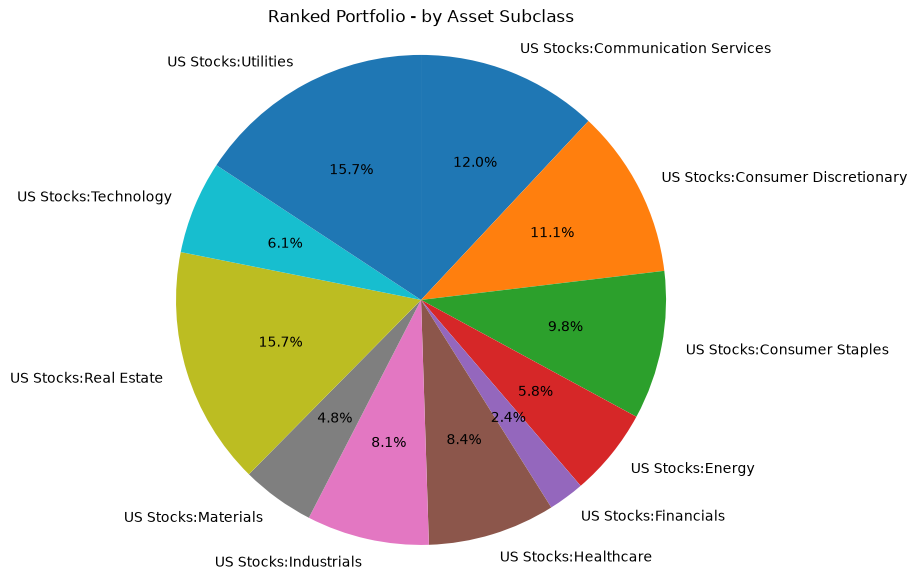

US Stocks:Communication Services   0.12
US Stocks:Consumer Discretionary   0.11
US Stocks:Consumer Staples         0.10
US Stocks:Energy                   0.06
US Stocks:Financials               0.02
US Stocks:Healthcare               0.08
US Stocks:Industrials              0.08
US Stocks:Materials                0.05
US Stocks:Real Estate              0.16
US Stocks:Technology               0.06
US Stocks:Utilities                0.16



In [14]:
# Show pie charts of investment and asset class weights
bb.show_pie_charts(df, portfolio_option, charts=['Investment Option', 'Asset Subclass'])

In [15]:
# Show exact weights
bb.print_portfolio(portfolio_option)

Ranked Portfolio Weights:
    MDU                            0.1573
    DBD                            0.0614
    CURB                           0.1573
    CENX                           0.0483
    VSTS                           0.0808
    PTGX                           0.0841
    DAVE                           0.0237
    KGS                            0.0580
    CHEF                           0.0981
    LAUR                           0.1113
    MSGS                           0.1197


### Optimize Portfolio

In [16]:
# Run_portfolio_optimizer = True will run portfolio optimizer after portfolio analysis is complete
run_portfolio_optimizer = False

In [17]:
# Optimize sharpe ratio while specifying Annual Rate, Worst Typical Down Year,
# and Black Swan.  Setting a constraint to None optimizes absolute Sharpe Ratio
# without regard to that constraint.

'''
constraints = {
    'Annual Return': 12,
    'Worst Typical Down Year': -5,
    'Black Swan': None
}
'''

constraints = {
    'Annual Return': 8,
    'Worst Typical Down Year': None,
    'Black Swan': -40
}

if run_portfolio_optimizer:
    bb.optimizer(df, portfolio_option, constraints)

### Use Sharpe Ratio adjusted weights
Recommend that you also try using Sharpe Ratio adjusted weights and compare those results with the Optimized Portflio.  
It tends to produce a higher Annual Return while keeping the allocations more balanced than the Optimizer.  (See 'Analysis Options' section).